# Coding Project 2: Credit Analytics

**Names of all group members:**


---

All code below is only suggestive and you may as well use different approaches.
Make sure that all requested quantities are printed or shown in tables/plots in the executed notebook.
A concise *Project Report* is required at the end of the notebook (see the last cells).

In [1]:
# Exercise 1.
import numpy as np
np.random.seed(0)  # for reproducibility

# simulate explanatory variables x (the age and monthly income are assumed here to follow a continuous uniform distribution)
m = 20000
n = 10000

# age in [18, 80], monthly income in [1, 15] (in CHF 1000), both unirmly distributed
x_1 = np.random.uniform(18, 80, size=(n+m, 1))  # age
x_2 = np.random.uniform(1, 15, size=(n+m, 1))  # monthly income

# 0: salaried, 1 = self-employed with probability of being self-employed = 0.1
x_3 = np.random.binomial(1, 0.1, size=(n+m, 1))  # employment status

# vector in R^3 of explanatory variables using only m training data points (the first m rows of x_1, x_2, and x_3)
x_ = np.hstack((x_1, x_2, x_3))

x_train = x_[:m, :]
x_test = x_[m:, :]
# a) calculate and print the empirical means and standard deviations over the training data (i = 1, ..., m)

print("Empirical means and standard deviations over the training data:")
print(" ")

for i, x in enumerate([x_1, x_2, x_3], start=1):
    print(f"Feature {i}: Mean = {np.mean(x[:m]):.2f}, Std = {np.std(x[:m]):.2f}")



# b) Can you come up with a few (2 or 3) additional features that may be relevant?
# (you don't have to implement those of course, just write down your answer in text)
#
print(" ")
print("Additional features that may be relevant:")
print("1. Family size: The number of dependents or family members could influence financial decisions and risk profiles.")
print("2. Net worth score: A person's net worth is a key indicator of their financial stability and ability to repay debt.")
print("3. Loan amount: The amount of the loan requested can impact the risk and terms of the loan.")


Empirical means and standard deviations over the training data:
 
Feature 1: Mean = 48.74, Std = 18.01
Feature 2: Mean = 7.99, Std = 4.03
Feature 3: Mean = 0.10, Std = 0.30
 
Additional features that may be relevant:
1. Family size: The number of dependents or family members could influence financial decisions and risk profiles.
2. Net worth score: A person's net worth is a key indicator of their financial stability and ability to repay debt.
3. Loan amount: The amount of the loan requested can impact the risk and terms of the loan.


In [2]:
# Exercise 2.
# Building the datasets:


# logistic sigmoid function
sigmoid = lambda x: 1. / (1. + np.exp(-x))

# random variables uniforml distirbuted
xi = np.random.uniform(0, 1, size=x_1.shape)

# probability that borrower i is "good" in 1,2
p_1 = sigmoid(13.3 - 0.33 *x_1 + 3.5 * x_2 - 3 * x_3)
p_2 = sigmoid(5 - 10 * ((x_1 < 25).astype(int) + (x_1 > 75).astype(int)) + 1.1 * x_2- x_3)

# build first and second datasets (with different underlying probabilities) 
y_1 = (xi <= p_1).astype(int)
y_2 = (xi <= p_2).astype(int)

y_1_train = y_1[:m]
y_2_train = y_2[:m]

y_1_test = y_1[m:]
y_2_test = y_2[m:]

# print xim ,p_1, y_1
print("First 5 samples of xi, p_1, and y_1:")
print(" ")
for i in range(5):
    print(f"xi[{i}] = {xi[i][0]:.4f}, p_1[{i}] = {p_1[i][0]:.4f}, y_1[{i}] = {y_1[i][0]}")

First 5 samples of xi, p_1, and y_1:
 
xi[0] = 0.1911, p_1[0] = 1.0000, y_1[0] = 1
xi[1] = 0.0585, p_1[1] = 1.0000, y_1[1] = 1
xi[2] = 0.4368, p_1[2] = 0.9993, y_1[2] = 1
xi[3] = 0.7203, p_1[3] = 1.0000, y_1[3] = 1
xi[4] = 0.8244, p_1[4] = 1.0000, y_1[4] = 1


In [3]:
# Exercise 2. a)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
# "model = LogisticRegression().fit(X_data, Y_data)" fits a model
# "pred_X = model.predict_proba(X)" evaluates the model
# (note that it outputs both P(Y=0|X) and P(Y=1|X))
# "log_loss(Y, pred_X)" evaluates the negative conditional log likelihood (also called cross-entropy loss)

# Fit the models on both datasets
model_1 = LogisticRegression().fit(x_train, y_1_train.ravel())  # Use only the training data for y_1
model_2 = LogisticRegression().fit(x_train, y_2_train.ravel())  # Use only the training data for y_2

pred_X_1= model_1.predict_proba(x_)
pred_X_2 = model_2.predict_proba(x_)

cross_entropy_loss_1_train = log_loss(y_1_train, pred_X_1[:m])  # Use only the training data for y_1
cross_entropy_loss_2_train = log_loss(y_2_train, pred_X_2[:m])

cross_entropy_loss_1_test = log_loss(y_1_test, pred_X_1[m:])  # Use only the test data for y_1
cross_entropy_loss_2_test = log_loss(y_2_test, pred_X_2[m:])


# Calculate and print the cross-entropy loss on both datasets for train and test

print("Cross-entropy loss on the training data:")
print(f"Dataset 1: {cross_entropy_loss_1_train:.4f}")
print(f"Dataset 2: {cross_entropy_loss_2_train:.4f}")
print(" ")
print("Cross-entropy loss on the test data:")
print(f"Dataset 1: {cross_entropy_loss_1_test:.4f}")
print(f"Dataset 2: {cross_entropy_loss_2_test:.4f}")


Cross-entropy loss on the training data:
Dataset 1: 0.0297
Dataset 2: 0.1535
 
Cross-entropy loss on the test data:
Dataset 1: 0.0349
Dataset 2: 0.1486


In [4]:
# Exercise 2. b)
# Calculate normalized data
# (as in the assignment: divide by the empirical standard deviations of the TRAINING data,
#  for both training and test data)

x_train_mean = np.mean(x_train, axis=0)
x_train_std = np.std(x_train, axis=0)

print("Training data standard deviation:", x_train_std)
print("We normalized by computing: x / std for each feature.")

x_train_normalized = x_train / x_train_std
x_test_normalized = x_test / x_train_std

# Standardized features are used only to compare with normalized features.
x_train_standardized = (x_train - x_train_mean) / x_train_std
x_test_standardized = (x_test - x_train_mean) / x_train_std


Training data standard deviation: [18.00743828  4.03080286  0.30225339]
We normalized by computing: x / std for each feature.


In [5]:
# Exercise 2.b) (i) and (ii)
from sklearn.svm import SVC
# "model = SVC(kernel='rbf', gamma=GAMMA, C=C, probability=True)" creates
# a model with kernel exp(-GAMMA \|x-x'\|_2^2) and regularization parameter C 
# (note the relation between C and the parameter lambda from the lecture).
# "probability=True" enables the option "model.predict_proba(X)" to predict probabilities from the regression function \hat{f}^{svm}.
# "model.fit(X, Y)" optimizes the model parameters (using hinge loss)

# from the assignment
gamma = 10e-2
C = 0.2



model_1_normalized = SVC(kernel='rbf', gamma=gamma, C=C, probability=True) 
model_2_normalized = SVC(kernel='rbf', gamma=gamma, C=C, probability=True)

model_1_stardardized = SVC(kernel='rbf', gamma=gamma, C=C, probability=True)
model_2_stardardized = SVC(kernel='rbf', gamma=gamma, C=C, probability=True)

# Fit the models for both datasets (this can take up to 60 seconds with SVC)
# Note: "model.fit(...)" modifies the model object in place, so use a separate model object
# for each dataset if you want to keep both fitted models.

model_1_normalized.fit(x_train_normalized, y_1_train.ravel())
model_2_normalized.fit(x_train_normalized, y_2_train.ravel())

model_1_stardardized.fit(x_train_standardized, y_1_train.ravel())
model_2_stardardized.fit(x_train_standardized, y_2_train.ravel())


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.1

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",0.2
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.1
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [6]:
# Exercise 2.b (iii)
# Predict probabilities on the combined training and test data so they can be split at m.

x_normalized = np.vstack((x_train_normalized, x_test_normalized))
x_standardized = np.vstack((x_train_standardized, x_test_standardized))

model_1_pred_normalized = model_1_normalized.predict_proba(x_normalized)
model_2_pred_normalized = model_2_normalized.predict_proba(x_normalized)

model_1_pred_standardized = model_1_stardardized.predict_proba(x_standardized)
model_2_pred_standardized = model_2_stardardized.predict_proba(x_standardized)

cross_entropy_loss_1_train_svm_normalized = log_loss(y_1_train, model_1_pred_normalized[:m])
cross_entropy_loss_2_train_svm_normalized = log_loss(y_2_train, model_2_pred_normalized[:m])
cross_entropy_loss_1_test_svm_normalized = log_loss(y_1_test, model_1_pred_normalized[m:])
cross_entropy_loss_2_test_svm_normalized = log_loss(y_2_test, model_2_pred_normalized[m:])

cross_entropy_loss_1_train_svm_standardized = log_loss(y_1_train, model_1_pred_standardized[:m])
cross_entropy_loss_2_train_svm_standardized = log_loss(y_2_train, model_2_pred_standardized[:m])
cross_entropy_loss_1_test_svm_standardized = log_loss(y_1_test, model_1_pred_standardized[m:])
cross_entropy_loss_2_test_svm_standardized = log_loss(y_2_test, model_2_pred_standardized[m:])

print("Cross-entropy loss on the training data (SVM, normalized):")
print(f"Dataset 1: {cross_entropy_loss_1_train_svm_normalized:.4f}")
print(f"Dataset 2: {cross_entropy_loss_2_train_svm_normalized:.4f}")
print("\nCross-entropy loss on the test data (SVM, normalized):")
print(f"Dataset 1: {cross_entropy_loss_1_test_svm_normalized:.4f}")
print(f"Dataset 2: {cross_entropy_loss_2_test_svm_normalized:.4f}")

print("\nDifference between normalized and standardized cross-entropy losses:")
print(f"Dataset 1, train: {cross_entropy_loss_1_train_svm_normalized - cross_entropy_loss_1_train_svm_standardized:.4f}")
print(f"Dataset 2, train: {cross_entropy_loss_2_train_svm_normalized - cross_entropy_loss_2_train_svm_standardized:.4f}")
print(f"Dataset 1, test: {cross_entropy_loss_1_test_svm_normalized - cross_entropy_loss_1_test_svm_standardized:.4f}")
print(f"Dataset 2, test: {cross_entropy_loss_2_test_svm_normalized - cross_entropy_loss_2_test_svm_standardized:.4f}")


Cross-entropy loss on the training data (SVM, normalized):
Dataset 1: 0.0319
Dataset 2: 0.0711

Cross-entropy loss on the test data (SVM, normalized):
Dataset 1: 0.0388
Dataset 2: 0.0671

Difference between normalized and standardized cross-entropy losses:
Dataset 1, train: 0.0000
Dataset 2, train: 0.0000
Dataset 1, test: -0.0000
Dataset 2, test: 0.0000


### Exercise 2.b (iv)
_Would the results change using standardized data instead of normalized data? No need to run any code here, only explain your reasoning._


No, the results do not change.

For any two observations $i,l$ (training or test), with $\hat\mu_j,\hat\sigma_j$ computed on the training data,
$$
\tilde z_{ij} - \tilde z_{lj}
= \frac{x_{ij}-\hat\mu_j}{\hat\sigma_j} - \frac{x_{lj}-\hat\mu_j}{\hat\sigma_j}
= \frac{x_{ij}}{\hat\sigma_j} - \frac{x_{lj}}{\hat\sigma_j}
= \tilde x_{ij} - \tilde x_{lj}.
$$
So we have that:
$$
k(\tilde z_i,\tilde z_l)
= \exp\Big(-\tfrac{1}{10}\sum_{j=1}^{3}(\tilde z_{ij}-\tilde z_{lj})^2\Big)
= \exp\Big(-\tfrac{1}{10}\sum_{j=1}^{3}(\tilde x_{ij}-\tilde x_{lj})^2\Big)
= k(\tilde x_i,\tilde x_l).
$$
The SVM fit depends on the data only through these kernel values and the labels $y_i$. So the dual coefficients $a^*$ and the intercept $b$ are identical, and so we have:
$$
\hat f^{\text{svm}}_s(\tilde z) = \sum_{i=1}^m a_i^* y_i\, k(\tilde z_i,\tilde z) + b
= \sum_{i=1}^m a_i^* y_i\, k(\tilde x_i,\tilde x) + b = \hat f^{\text{svm}}_s(\tilde x).
$$

Furthermore, we also showed empirically in the code that they produce the same loss.



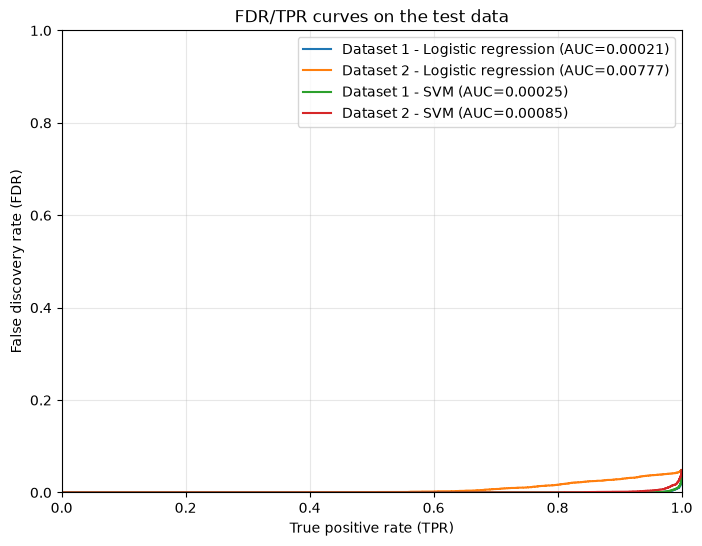

Dataset 1 - Logistic regression: 0.00021
Dataset 1 - SVM: 0.00025
Dataset 2 - Logistic regression: 0.00777
Dataset 2 - SVM: 0.00085
Dataset 1: Logistic regression has the lower FDR/TPR AUC.
Dataset 2: SVM has the lower FDR/TPR AUC.


In [7]:
# Exercise 2.c
# Plot the FDR/TPR-curves with the TPR on the horizontal axis and the FDR on the vertical axis,
# and compute the AUC of each plotted curve on the test data.

import matplotlib.pyplot as plt

# Thresholds c: you may use all distinct predicted probabilities (this gives the exact curve), or a grid of
# values in [0, 1]. A uniform grid such as np.linspace(0, 1, 100) can be too coarse when many predicted
# probabilities are very close to 1. Check that your curve covers TPR values from (close to) 0 to 1.

# To approximately calculate the AUC, it is fine to simply use Riemann sums.
# This means, if you have N (a_i, b_i) pairs for the curves, ordered such that a_1 <= a_2 <= ... <= a_N,
# then you may simply use the sum
# sum_{i=1}^{N-1} (b_i + b_{i+1})/2 * (a_{i+1}-a_i)
# as the approximation of the integral (or AUC)

# Exact curve: every distinct predicted probability is a threshold c (classify as good if p >= c).
# Sorting by decreasing probability, cumulative sums give TP and FP for all thresholds at once;
# tied probabilities are grouped so each threshold appears once.
def plot_fdr_tpr(y_true, probabilities, label):
    y_true = np.asarray(y_true).ravel()
    probabilities = np.asarray(probabilities).ravel()
    positives = np.sum(y_true == 1)  # depends only on the dataset

    order = np.argsort(-probabilities, kind="stable")
    scores = probabilities[order]
    labels = y_true[order]
    tp = np.cumsum(labels == 1)  # true positives for each threshold
    fp = np.cumsum(labels == 0)  # false positives for each threshold
    group_ends = np.r_[scores[:-1] != scores[1:], True]
    tp, fp = tp[group_ends], fp[group_ends]

    tpr = np.r_[0, tp / positives]
    fdr = np.r_[0, fp / (tp + fp)]  # FDR is set to 0 at TPR = 0 (no loans granted)
    auc = np.sum((fdr[:-1] + fdr[1:]) / 2 * np.diff(tpr))  # Riemann (trapezoidal) sum

    plt.plot(tpr, fdr, label=f"{label} (AUC={auc:.5f})")
    return auc

plt.figure(figsize=(8, 6))

# (the same function is reused for all four cases)
auc_logistic_1 = plot_fdr_tpr(y_1_test, pred_X_1[m:, 1], "Dataset 1 - Logistic regression")
auc_logistic_2 = plot_fdr_tpr(y_2_test, pred_X_2[m:, 1], "Dataset 2 - Logistic regression")
auc_svm_1 = plot_fdr_tpr(y_1_test, model_1_pred_normalized[m:, 1], "Dataset 1 - SVM")
auc_svm_2 = plot_fdr_tpr(y_2_test, model_2_pred_normalized[m:, 1], "Dataset 2 - SVM")

plt.xlabel("True positive rate (TPR)")
plt.ylabel("False discovery rate (FDR)")
plt.title("FDR/TPR curves on the test data")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Print the AUC values.
print(f"Dataset 1 - Logistic regression: {auc_logistic_1:.5f}")
print(f"Dataset 1 - SVM: {auc_svm_1:.5f}")
print(f"Dataset 2 - Logistic regression: {auc_logistic_2:.5f}")
print(f"Dataset 2 - SVM: {auc_svm_2:.5f}")

# A lower FDR/TPR AUC means a lower average false discovery rate across TPR values.
# Compare logistic regression and the normalized-feature SVM separately on each data set.
for dataset, logistic_auc, svm_auc in [("Dataset 1", auc_logistic_1, auc_svm_1), ("Dataset 2", auc_logistic_2, auc_svm_2)]:
    better_model = "Logistic regression" if logistic_auc < svm_auc else "SVM"
    print(f"{dataset}: {better_model} has the lower FDR/TPR AUC.")


### Exercise 2.c: interpretation

**Construction**
- For each threshold $c$, classify applicant $i$ as "good" if $\hat p(x_i)\ge c$, using the test data; all distinct predicted probabilities are used as thresholds (exact curve).
- $\mathrm{TPR}(c)=\mathrm{TP}/(\text{all good borrowers})$ and $\mathrm{FDR}(c)=\mathrm{FP}/(\mathrm{TP}+\mathrm{FP})$, the share of delinquent borrowers among accepted loans.
- Sorting by decreasing probability gives TP and FP for all thresholds via cumulative sums; the AUC is the  Riemann sum over TPR.

**Meaning of the AUC**
- It is the average FDR over all TPR levels: the average share of bad loans in the accepted portfolio, while accepting from 0% to 100% of the good borrowers.
- Lower is better (the opposite of the usual ROC-AUC). Values are small because most borrowers are good.

**Comparison**
- Dataset 1: logistic regression is slightly better (0.00021 vs 0.00025). The model is correctly specified; the two are practically equal.
- Dataset 2: SVM is about 9 times better (0.00085 vs 0.00777). Logistic regression is linear in age and cannot capture the higher default risk for age $<25$ and $>75$; the RBF kernel can.


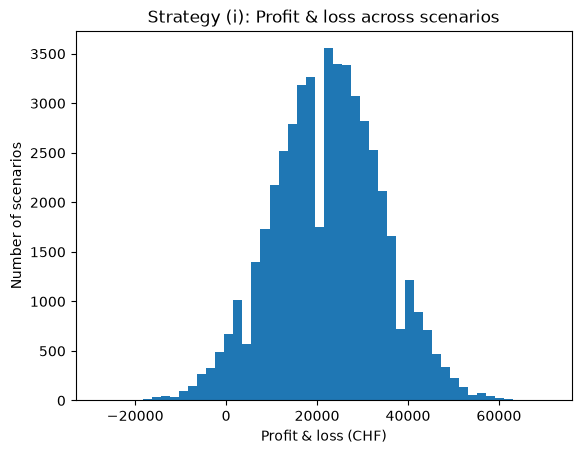

Expected P&L: CHF 22,380.05
95%-VaR: CHF -2,455.00


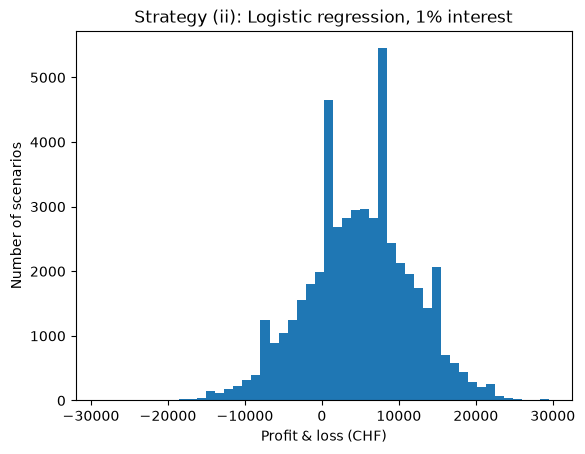

Strategy (ii) — loans: 6992; expected P&L: CHF 4,888.81; 95%-VaR: CHF 6,840.00


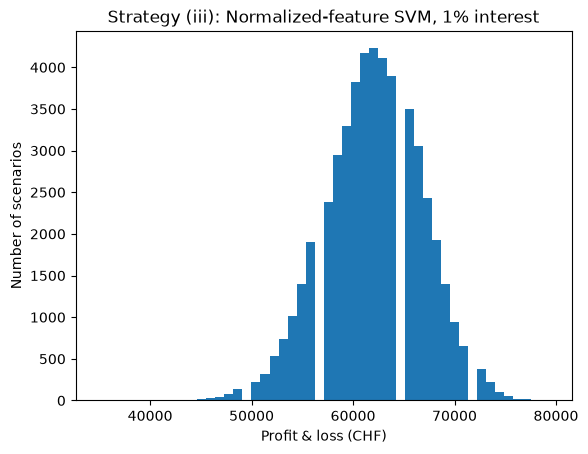

Strategy (iii) — loans: 8841; expected P&L: CHF 62,006.52; 95%-VaR: CHF -54,070.00
 
Comparison of strategies:
 
Highest estimated expected P&L: Strategy (iii) Normalized SVM, 1% (CHF 62,006.52).
Lowest estimated 95%-VaR: Strategy (iii) Normalized SVM, 1% (CHF -54,070.00).
Selective strategies issue fewer loans and use the same 1% rate so their performance depends on how well each model identifies reliable borrowers.


In [9]:
# Exercise 3.

# Set model parameters and define matrix D
# (D has n x 50000 = 5*10^8 entries: a float64 array of uniforms of this size needs about 4 GB of memory.
#  If your machine runs out of memory, consider generating D in blocks of columns and/or storing it as booleans.)

n_scenarios = 50_000
loan_amount = 1_000
interest_rate = 0.055
chunk_size = 1_000

# Strategy (i):
# We give out a loan to every person in the test data set in the amount of CHF 1000 charging an
# interest rate of 5.5%.
# Define Portfolio and possible outcomes for this portfolio using matrix D

p_good_test = np.asarray(p_2[m:]).reshape(n, 1)
D = np.empty((n, n_scenarios), dtype=bool)

for start in range(0, n_scenarios, chunk_size):
    stop = min(start + chunk_size, n_scenarios)
    uniforms = np.random.random((n, stop - start))
    D[:, start:stop] = uniforms <= p_good_test

Portfolio_i = np.ones(n, dtype=bool)
repaid_count = D.sum(axis=0)
profit_i = (
    repaid_count * loan_amount * interest_rate
    - (Portfolio_i.sum() - repaid_count) * loan_amount)

# Plot histogram of profits and losses

import matplotlib.pyplot as plt

plt.hist(profit_i, bins=50)
plt.xlabel("Profit & loss (CHF)")
plt.ylabel("Number of scenarios")
plt.title("Strategy (i): Profit & loss across scenarios")
plt.show()

# Calculate expected profit and losses and 95%-VaR

expected_profit_i = profit_i.mean()
var95_i = -np.quantile(profit_i, 0.05)

print(f"Expected P&L: CHF {expected_profit_i:,.2f}")
print(f"95%-VaR: CHF {var95_i:,.2f}")

# Strategy (ii):
# Select applicants with logistic-regression predicted repayment probability >= 95%.
interest_rate_selective = 0.01
prob_logistic_test = pred_X_2[m:, 1]
Portfolio_ii = prob_logistic_test >= 0.95
repaid_count_ii = D[Portfolio_ii].sum(axis=0)
loans_ii = Portfolio_ii.sum()
profit_ii = (
    repaid_count_ii * loan_amount * interest_rate_selective
    - (loans_ii - repaid_count_ii) * loan_amount
)

# Plot histogram of profits and losses.
plt.hist(profit_ii, bins=50)
plt.xlabel("Profit & loss (CHF)")
plt.ylabel("Number of scenarios")
plt.title("Strategy (ii): Logistic regression, 1% interest")
plt.show()

# Calculate expected profit and loss and 95%-VaR.
expected_profit_ii = profit_ii.mean()
var95_ii = -np.quantile(profit_ii, 0.05)
print(f"Strategy (ii) — loans: {loans_ii}; expected P&L: CHF {expected_profit_ii:,.2f}; 95%-VaR: CHF {var95_ii:,.2f}")

# Strategy (iii): Select applicants using normalized-feature SVM probabilities >= 95%.
prob_svm_test = model_2_pred_normalized[m:, 1]
Portfolio_iii = prob_svm_test >= 0.95
repaid_count_iii = D[Portfolio_iii].sum(axis=0)
loans_iii = Portfolio_iii.sum()
profit_iii = (repaid_count_iii * loan_amount * interest_rate_selective
    - (loans_iii - repaid_count_iii) * loan_amount)

# Plot histogram of profits and losses.
plt.hist(profit_iii, bins=50)
plt.xlabel("Profit & loss (CHF)")
plt.ylabel("Number of scenarios")
plt.title("Strategy (iii): Normalized-feature SVM, 1% interest")
plt.show()

# Calculate expected profit and loss and 95%-VaR.
expected_profit_iii = profit_iii.mean()
var95_iii = -np.quantile(profit_iii, 0.05)
print(f"Strategy (iii) — loans: {loans_iii}; expected P&L: CHF {expected_profit_iii:,.2f}; 95%-VaR: CHF {var95_iii:,.2f}")

# c) Compare strategies using simulated expected P&L and downside risk.
strategies = [
    ("(i) All applicants, 5.5%", expected_profit_i, var95_i),
    ("(ii) Logistic regression, 1%", expected_profit_ii, var95_ii),
    ("(iii) Normalized SVM, 1%", expected_profit_iii, var95_iii),
]
best_expected = max(strategies, key=lambda item: item[1])
lowest_var = min(strategies, key=lambda item: item[2])
print(" ")
print("Comparison of strategies:")
print(" ")
print(f"Highest estimated expected P&L: Strategy {best_expected[0]} (CHF {best_expected[1]:,.2f}).")
print(f"Lowest estimated 95%-VaR: Strategy {lowest_var[0]} (CHF {lowest_var[2]:,.2f}).")
print("Selective strategies issue fewer loans and use the same 1% rate so their performance depends on how well each model identifies reliable borrowers.")


### Project Report

At the end of the notebook, provide a concise synthesis of your analysis. Do not simply repeat every answer above.

#### Approach
Briefly summarize how you generated the data, which models you fitted, and how you evaluated them and the lending strategies.

- **Data:** `m = 20,000` train and `n = 10,000` test borrowers (age, income, self-employed; seed 0). Labels $y = \mathbb 1\{\xi \le p_s(x)\}$: set 1 has linear log-odds, set 2 a non-linear age effect (extra risk if age $<25$ or $>75$).
- **Models:** logistic regression (raw features) and RBF-SVM with Platt scaling (`gamma=0.1`, `C=0.2`, normalized features), fitted on both sets.
- **Evaluation:** cross-entropy (`log_loss`) and FDR/TPR AUC (`plot_fdr_tpr`) on test data. Strategies (set 2): P&L in each of the 50,000 scenarios of `D` (drawn with the true $p_2$, shared by all strategies), then histogram, mean and 95%-VaR.

#### Model selection
Explain which classifier you would rely on for the lending decision and why. (The model hyperparameters are fixed by the assignment; no hyperparameter tuning is required.)

- **Classifier: SVM.** Set 1: almost equal (logistic slightly better, test cross-entropy 0.0349 vs 0.0388, as it is the correct model). Set 2: SVM much better (0.0671 vs 0.1486), since logistic regression is linear in age and misses the risk of young and old applicants. The true $p$ is unknown in practice, so the SVM is the safer choice: it loses little if $p$ is linear and gains a lot if not. Train and test losses are close (no overfitting).
- **Strategy: (iii)** (SVM, $\hat p \ge 0.95$, 1%): highest expected P&L, lowest VaR. In our sample (ii) is even worse than (i): a wrong model makes selection counterproductive.

#### Key results
Summarize the most important quantitative results.

| Test (lower = better) | Set 1 logistic | Set 1 SVM | Set 2 logistic | Set 2 SVM |
|---|---|---|---|---|
| Cross-entropy | 0.0349 | 0.0388 | 0.1486 | 0.0671 |
| FDR/TPR AUC | 0.00021 | 0.00025 | 0.00777 | 0.00085 |

| Strategy | Loans | Expected P&L (CHF) | 95%-VaR (CHF) |
|---|---|---|---|
| (i) everyone, 5.5% | 10,000 | ≈ 22,000 | -2,455 |
| (ii) logistic $\hat p \ge 0.95$, 1% | 6,992 | ≈ 4,900 | 6,840 |
| (iii) SVM $\hat p \ge 0.95$, 1% | 8,841 | ≈ 62,000 | -54,070 |

- On set 2 the SVM has about 2× lower cross-entropy and 9× lower AUC; on set 1 the models are practically equal.
- A negative VaR is a gain: in 95% of scenarios (i) earns at least CHF 2,455 and (iii) at least CHF 54,070; in (ii) the worst 5% lose at least CHF 6,840.

#### Interpretation
Explain what the results imply about the classification methods and the lending problem.

- **Model class matters if the truth is non-linear.** Logistic regression suffices for linear log-odds (set 1). On set 2 it cannot capture the age effect and decides mostly on income; the SVM can. (AUC = average share of bad loans in the portfolio over all acceptance levels; small because most borrowers are good.)
- **Margins are thin.** A default loses CHF 1,000; a repaid loan earns CHF 55 (5.5%) or 10 (1%). So the portfolio default rate must stay below $\approx r/(1+r)$: 5.2% for (i), 1% for (ii) and (iii). Implied rates:
  - (i) ≈ 5.0%: just below break-even, modest profit.
  - (ii) ≈ 0.9%: barely below. Ignoring age, it accepts risky young/old and rejects safe middle-aged applicants: small profit, positive VaR.
  - (iii) ≈ 0.3%: far below, large profit, almost no losses.
- **Model quality = money:** the SVM instead of logistic regression adds about CHF 57,000 of expected P&L. At 1% interest, selection only pays with a good model.

#### Robustness
Discuss how strongly your conclusions could depend on random elements of the analysis (e.g. simulation noise in the data and in the market scenarios). No additional experiments are required.

- **Scenario noise is small:** the standard error of an expected P&L is about CHF 20–50; the VaR moves in steps of about CHF 1,000 (one default).
- **Data noise matters more:** one draw (seed 0) of borrowers, labels and models. `D` only adds noise on one test set with about 500 delinquent borrowers, so small gaps (e.g. AUC on set 1) mean little.
- **3 other seeds** (run separately, not in this notebook): "(iii) is best" (expected P&L CHF 62–68k) and "SVM beats logistic on set 2" always hold. (i) vs (ii) does not (expected P&L from CHF -11k to +31k, order swaps), as both are near break-even.

#### Limitations
State the main limitations of the analysis, the models, and the modelling assumptions.

- **Data:** synthetic, 3 features, simple known $p$. Real data have more features (e.g. credit history), noise and selection bias (repayment is only seen for accepted loans).
- **Models:** fixed hyperparameters; no non-linear features for logistic regression; Platt probabilities are approximate near 1, where the 95% threshold lies; the SVM is less transparent.
- **Scenarios and P&L:** true $p_2$ (unknown to a real lender), no drift, independent defaults (in reality they cluster, e.g. in a recession, so tail risk is higher), all-or-nothing loans (no recovery), no costs, fixed interest. VaR ignores losses beyond the 5%-quantile (Expected Shortfall would capture them).